# 17 GHSL Six-City Three-Product Actual-vs-Predicted Evaluation

This notebook creates presentation-ready comparisons of predicted versus actual values for the six existing cities in the two held-out target epochs:

- **2010→2015 validation**
- **2015→2020 test**

Products evaluated:

1. **GHS-BUILT-S:** `built_surface_total_m2`, Linear Regression versus persistence.
2. **GHS-POP:** `population_total`, Linear Regression versus persistence.
3. **GHS-SMOD / Degree of Urbanisation:** `smod_class`, Random Forest versus current-class persistence.

The notebook does not train models. It joins the already persisted prediction outputs, exports cell-level CSV files, recomputes metrics, and produces overall, city-wise, spatial, hotspot, confusion-matrix, and error-distribution figures.

All EC2/HDFS/Spark work uses `/content/drive/MyDrive/remote_exec.sh`. Run one cell at a time.

In [1]:
# ============================================================
# CELL 1: BOOTSTRAP AND PATHS
# ============================================================
from google.colab import drive
from pathlib import Path
from IPython.display import display
import base64, csv, json, os, shutil, subprocess, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

drive.mount('/content/drive',force_remount=False)
D=Path('/content/drive/MyDrive');REMOTE_EXEC=D/'remote_exec.sh';KEY=D/'hadoop-hdfs.pem';LOCAL_KEY=Path('/content/hadoop-hdfs.pem')
ART=D/'GHSL_Urban_Growth_Model'/'six_city_three_product_evaluation_v1';FIG=ART/'figures';SPATIAL=FIG/'spatial';ART.mkdir(parents=True,exist_ok=True);FIG.mkdir(exist_ok=True);SPATIAL.mkdir(exist_ok=True)
for p in [REMOTE_EXEC,KEY]:
    if not p.is_file():raise FileNotFoundError(str(p))
REMOTE_EXEC.chmod(0o700)
if LOCAL_KEY.exists():LOCAL_KEY.unlink()
shutil.copy2(KEY,LOCAL_KEY);LOCAL_KEY.chmod(0o600)
def run_remote(command,timeout=300,show_output=True,raise_on_error=True):
    r=subprocess.run(['bash',str(REMOTE_EXEC),command],text=True,capture_output=True,timeout=timeout)
    if show_output and r.stdout:print(r.stdout)
    if show_output and r.stderr:print('REMOTE STDERR:');print(r.stderr)
    if raise_on_error and r.returncode!=0:raise RuntimeError('Remote command failed with return code '+str(r.returncode))
    return r
BUILT_PRED='/data/ghsl/modeling/evaluation/six_city_2015_2020_v1/linear_regression_predictions'
OTHER_PRED='/data/ghsl/modeling/evaluation/six_city_population_smod_v1/cell_predictions'
COMBINED='/data/ghsl/modeling/evaluation/six_city_three_product_v1/cell_predictions'
SUMMARY='/data/ghsl/modeling/evaluation/six_city_three_product_v1/summary_tables'
CITY_LABELS={'bengaluru':'Bengaluru','chennai_metro':'Chennai Metropolitan Region','delhi_ncr':'Delhi NCR','hyderabad':'Hyderabad','mumbai_metro':'Mumbai Metropolitan Region','pune_metro':'Pune Metropolitan Region'}
print('Output:',ART);print('CELL 1: SUCCESS')

Mounted at /content/drive
Output: /content/drive/MyDrive/GHSL_Urban_Growth_Model/six_city_three_product_evaluation_v1
CELL 1: SUCCESS


In [2]:
# ============================================================
# CELL 2: PREFLIGHT
# ============================================================
cmd=r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop;export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"
for p in /data/ghsl/modeling/evaluation/six_city_2015_2020_v1/linear_regression_predictions /data/ghsl/modeling/evaluation/six_city_population_smod_v1/cell_predictions;do hdfs dfs -test -e "$p";done
if hdfs dfs -test -e /data/ghsl/modeling/evaluation/six_city_three_product_v1;then echo 'ERROR: combined output already exists';exit 30;fi
echo THREE_PRODUCT_EVALUATION_PREFLIGHT_SUCCESS
"""
run_remote(cmd,300);print('CELL 2: SUCCESS')

THREE_PRODUCT_EVALUATION_PREFLIGHT_SUCCESS

REMOTE STDERR:

CELL 2: SUCCESS


In [3]:
# ============================================================
# CELL 3: JOIN ALL THREE PREDICTION PRODUCTS AND BUILD METRICS
# ============================================================
payload=base64.b64encode(json.dumps({'built':BUILT_PRED,'other':OTHER_PRED,'combined':COMBINED,'summary':SUMMARY}).encode()).decode()
cmd=r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop;export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"
P=/tmp/nb17_payload.json;S=/tmp/nb17_join.py;echo __P__|base64 -d > "$P"
cat > "$S" <<'PY_REMOTE'
from pyspark.sql import SparkSession,functions as F
from pyspark.ml.evaluation import RegressionEvaluator
import json,sys
p=json.load(open(sys.argv[1]));s=SparkSession.builder.appName('Six-City-Three-Product-Evaluation').getOrCreate();s.sparkContext.setLogLevel('WARN')
try:
 fs=s._jvm.org.apache.hadoop.fs.FileSystem.get(s._jsc.hadoopConfiguration())
 for x in [p['combined'],p['summary']]:
  if fs.exists(s._jvm.org.apache.hadoop.fs.Path(x)):raise RuntimeError('Refusing overwrite: '+x)
 keys=['city_slug','grid_cell_id','from_epoch','to_epoch']
 b=s.read.parquet(p['built']).select(*keys,'grid_1km_row','grid_1km_col','grid_min_x','grid_max_x','grid_min_y','grid_max_y',F.col('label').cast('double').alias('actual_built_surface_m2'),F.col('current_built_surface_m2').cast('double').alias('current_built_surface_m2'),F.col('model_prediction').cast('double').alias('predicted_built_surface_m2'),F.col('persistence_prediction').cast('double').alias('built_persistence_m2'))
 o=s.read.parquet(p['other']).select(*keys,F.col('population_total').cast('double').alias('current_population'),F.col('next_population_total').cast('double').alias('actual_population'),F.col('lr_population_prediction').cast('double').alias('predicted_population'),F.col('population_persistence').cast('double').alias('population_persistence'),F.col('smod_class').cast('string').alias('current_smod_class'),F.col('smod_actual').cast('string').alias('actual_smod_class'),F.col('smod_prediction_string').cast('string').alias('predicted_smod_class'),F.col('smod_persistence').cast('string').alias('smod_persistence'))
 q=(b.join(o,keys,'inner').withColumn('actual_built_growth_m2',F.col('actual_built_surface_m2')-F.col('current_built_surface_m2')).withColumn('predicted_built_growth_m2',F.col('predicted_built_surface_m2')-F.col('current_built_surface_m2')).withColumn('built_error_m2',F.col('predicted_built_surface_m2')-F.col('actual_built_surface_m2')).withColumn('actual_population_change',F.col('actual_population')-F.col('current_population')).withColumn('predicted_population_change',F.col('predicted_population')-F.col('current_population')).withColumn('population_error',F.col('predicted_population')-F.col('actual_population')).withColumn('smod_correct',F.col('predicted_smod_class')==F.col('actual_smod_class')).withColumn('smod_persistence_correct',F.col('smod_persistence')==F.col('actual_smod_class')))
 if q.count()!=58800 or q.select(*keys).distinct().count()!=58800:raise RuntimeError('Join validation failed')
 q.repartition('to_epoch','city_slug').write.mode('errorifexists').partitionBy('to_epoch','city_slug').parquet(p['combined'])
 def reg(x,label,pred):
  z=x.withColumn('ep',F.col(pred));return {m:RegressionEvaluator(labelCol=label,predictionCol='ep',metricName=m).evaluate(z) for m in ['mae','rmse','r2']}
 rows=[]
 cities=sorted(r[0] for r in q.select('city_slug').distinct().collect())
 for e in [2015,2020]:
  x=q.filter(F.col('to_epoch')==e)
  for scope,city,y in [('overall','ALL',x)]+[('city',c,x.filter(F.col('city_slug')==c)) for c in cities]:
   n=y.count();k=max(1,int(round(n*.10)))
   def hotspot(actual,pred):
    a={r[0] for r in y.orderBy(F.desc(actual)).select(F.concat_ws(':','city_slug','grid_cell_id')).limit(k).collect()};b={r[0] for r in y.orderBy(F.desc(pred)).select(F.concat_ws(':','city_slug','grid_cell_id')).limit(k).collect()};return len(a&b)/k
   rows.append({'to_epoch':e,'scope':scope,'city_slug':city,'rows':n,'built_model':reg(y,'actual_built_surface_m2','predicted_built_surface_m2'),'built_persistence':reg(y,'actual_built_surface_m2','built_persistence_m2'),'built_growth_hotspot_f1':hotspot('actual_built_growth_m2','predicted_built_growth_m2'),'population_model':reg(y,'actual_population','predicted_population'),'population_persistence':reg(y,'actual_population','population_persistence'),'population_growth_hotspot_f1':hotspot('actual_population_change','predicted_population_change'),'smod_accuracy':y.filter('smod_correct').count()/n,'smod_persistence_accuracy':y.filter('smod_persistence_correct').count()/n})
 confusion=[r.asDict() for r in q.groupBy('to_epoch','actual_smod_class','predicted_smod_class').count().orderBy('to_epoch','actual_smod_class','predicted_smod_class').collect()]
 flat=[]
 for r in rows:flat.append({'to_epoch':r['to_epoch'],'scope':r['scope'],'city_slug':r['city_slug'],'rows':r['rows'],'built_mae':r['built_model']['mae'],'built_rmse':r['built_model']['rmse'],'built_r2':r['built_model']['r2'],'built_persistence_mae':r['built_persistence']['mae'],'built_persistence_rmse':r['built_persistence']['rmse'],'built_hotspot_f1':r['built_growth_hotspot_f1'],'population_mae':r['population_model']['mae'],'population_rmse':r['population_model']['rmse'],'population_r2':r['population_model']['r2'],'population_persistence_mae':r['population_persistence']['mae'],'population_persistence_rmse':r['population_persistence']['rmse'],'population_hotspot_f1':r['population_growth_hotspot_f1'],'smod_accuracy':r['smod_accuracy'],'smod_persistence_accuracy':r['smod_persistence_accuracy']})
 s.createDataFrame(flat).write.mode('errorifexists').parquet(p['summary']+'/metrics');s.createDataFrame(confusion).write.mode('errorifexists').parquet(p['summary']+'/smod_confusion')
 print('METRICS_BEGIN');print(json.dumps({'metrics':rows,'confusion':confusion},sort_keys=True));print('METRICS_END');print('THREE_PRODUCT_JOIN_SUCCESS')
finally:s.stop()
PY_REMOTE
python3 -m py_compile "$S";spark-submit --master local[2] --driver-memory 5g --conf spark.ui.enabled=false --conf spark.sql.shuffle.partitions=24 "$S" "$P";rm -f "$S" "$P"
""".replace('__P__',payload)
r=run_remote(cmd,10800,show_output=False)
if 'THREE_PRODUCT_JOIN_SUCCESS' not in r.stdout:
 print(r.stdout[-16000:]);print(r.stderr[-8000:]);raise RuntimeError('Join/evaluation failed')
RESULTS=json.loads(r.stdout.split('METRICS_BEGIN',1)[1].split('METRICS_END',1)[0].strip())
print('Metric records:',len(RESULTS['metrics']));print('Confusion records:',len(RESULTS['confusion']));print('CELL 3: SUCCESS')

Metric records: 14
Confusion records: 69
CELL 3: SUCCESS


In [4]:
# ============================================================
# CELL 4: EXPORT 2015 AND 2020 CELL-LEVEL COMBINED CSV FILES
# ============================================================
cmd=r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop;export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"
hdfs dfs -rm -r -skipTrash /tmp/nb17_export >/dev/null 2>&1||true
S=/tmp/nb17_export.py
cat > "$S" <<'PY_REMOTE'
from pyspark.sql import SparkSession
s=SparkSession.builder.appName('Three-Product-CSV-Export').getOrCreate();s.sparkContext.setLogLevel('WARN')
try:
 d=s.read.parquet('/data/ghsl/modeling/evaluation/six_city_three_product_v1/cell_predictions')
 for e in [2015,2020]:d.filter(d.to_epoch==e).orderBy('city_slug','grid_cell_id').coalesce(1).write.mode('overwrite').option('header',True).csv('/tmp/nb17_export/'+str(e))
finally:s.stop()
PY_REMOTE
spark-submit --master local[1] --driver-memory 4g --conf spark.ui.enabled=false "$S";rm -f "$S"
"""
run_remote(cmd,3600,show_output=False)
for e in [2015,2020]:
 r=run_remote("source /home/ubuntu/ghsl-sedona-env.sh;export HADOOP_HOME=/usr/local/hadoop;export PATH=$HADOOP_HOME/bin:$PATH;P=$(hdfs dfs -find /tmp/nb17_export/"+str(e)+" -name 'part-*.csv'|head -1);hdfs dfs -cat \"$P\"",1800,show_output=False);p=ART/f'six_city_three_product_{e}_cell_predictions.csv';p.write_text(r.stdout,encoding='utf-8');print('Saved',p,'rows',sum(1 for _ in p.open())-1)
run_remote("source /home/ubuntu/ghsl-sedona-env.sh;export HADOOP_HOME=/usr/local/hadoop;export PATH=$HADOOP_HOME/bin:$PATH;hdfs dfs -rm -r -skipTrash /tmp/nb17_export",600,show_output=False)
metrics_df=pd.json_normalize(RESULTS['metrics']);confusion_df=pd.DataFrame(RESULTS['confusion']);metrics_df.to_csv(ART/'three_product_metrics.csv',index=False);confusion_df.to_csv(ART/'smod_confusion.csv',index=False);(ART/'three_product_metrics.json').write_text(json.dumps(RESULTS,indent=2,sort_keys=True)+'\n')
print('CELL 4: SUCCESS')

Saved /content/drive/MyDrive/GHSL_Urban_Growth_Model/six_city_three_product_evaluation_v1/six_city_three_product_2015_cell_predictions.csv rows 29400
Saved /content/drive/MyDrive/GHSL_Urban_Growth_Model/six_city_three_product_evaluation_v1/six_city_three_product_2020_cell_predictions.csv rows 29400
CELL 4: SUCCESS


In [5]:
# ============================================================
# CELL 5: DISPLAY OVERALL AND CITY-WISE COMPARISON TABLES
# ============================================================
flat=[]
for r in RESULTS['metrics']:
 flat.append({'Year':r['to_epoch'],'Scope':r['scope'],'City':CITY_LABELS.get(r['city_slug'],r['city_slug']),'Product':'Built surface','MAE':r['built_model']['mae'],'RMSE':r['built_model']['rmse'],'R² / Accuracy':r['built_model']['r2'],'Persistence RMSE / Accuracy':r['built_persistence']['rmse'],'Hotspot F1':r['built_growth_hotspot_f1']})
 flat.append({'Year':r['to_epoch'],'Scope':r['scope'],'City':CITY_LABELS.get(r['city_slug'],r['city_slug']),'Product':'Population','MAE':r['population_model']['mae'],'RMSE':r['population_model']['rmse'],'R² / Accuracy':r['population_model']['r2'],'Persistence RMSE / Accuracy':r['population_persistence']['rmse'],'Hotspot F1':r['population_growth_hotspot_f1']})
 flat.append({'Year':r['to_epoch'],'Scope':r['scope'],'City':CITY_LABELS.get(r['city_slug'],r['city_slug']),'Product':'Degree of Urbanisation','MAE':np.nan,'RMSE':np.nan,'R² / Accuracy':r['smod_accuracy'],'Persistence RMSE / Accuracy':r['smod_persistence_accuracy'],'Hotspot F1':np.nan})
TABLE=pd.DataFrame(flat)
print('OVERALL THREE-PRODUCT PERFORMANCE');display(TABLE[TABLE.Scope=='overall'].style.format({'MAE':'{:,.2f}','RMSE':'{:,.2f}','R² / Accuracy':'{:.4f}','Persistence RMSE / Accuracy':'{:.4f}','Hotspot F1':'{:.2%}'}))
print('CITY-WISE 2020 PERFORMANCE');display(TABLE[(TABLE.Scope=='city')&(TABLE.Year==2020)].style.format({'MAE':'{:,.2f}','RMSE':'{:,.2f}','R² / Accuracy':'{:.4f}','Persistence RMSE / Accuracy':'{:.4f}','Hotspot F1':'{:.2%}'}))
print('CELL 5: SUCCESS')

OVERALL THREE-PRODUCT PERFORMANCE


,Year,Scope,City,Product,MAE,RMSE,R² / Accuracy,Persistence RMSE / Accuracy,Hotspot F1
0,2015,overall,ALL,Built surface,"5,904.54","10,700.97",0.9912,16138.4614,55.54%
1,2015,overall,ALL,Population,288.33,713.86,0.9939,958.6356,68.64%
2,2015,overall,ALL,Degree of Urbanisation,nan,nan,0.9192,0.9135,nan%
21,2020,overall,ALL,Built surface,"6,961.29","10,977.95",0.9910,12107.3659,36.60%
22,2020,overall,ALL,Population,305.70,644.63,0.9958,972.8240,77.14%
23,2020,overall,ALL,Degree of Urbanisation,nan,nan,0.8938,0.8890,nan%


CITY-WISE 2020 PERFORMANCE


,Year,Scope,City,Product,MAE,RMSE,R² / Accuracy,Persistence RMSE / Accuracy,Hotspot F1
24,2020,city,Bengaluru,Built surface,"7,837.40","11,608.83",0.9900,15341.4531,34.90%
25,2020,city,Bengaluru,Population,492.31,"1,137.99",0.9877,1647.4258,68.98%
26,2020,city,Bengaluru,Degree of Urbanisation,nan,nan,0.8418,0.8351,nan%
27,2020,city,Chennai Metropolitan Region,Built surface,"6,798.71","10,656.73",0.9900,7309.8729,41.63%
28,2020,city,Chennai Metropolitan Region,Population,210.22,320.53,0.9976,497.7238,83.67%
29,2020,city,Chennai Metropolitan Region,Degree of Urbanisation,nan,nan,0.9520,0.9545,nan%
30,2020,city,Delhi NCR,Built surface,"8,626.98","12,719.83",0.9928,16770.3063,39.18%
31,2020,city,Delhi NCR,Population,421.38,702.45,0.9964,1324.0786,77.96%
32,2020,city,Delhi NCR,Degree of Urbanisation,nan,nan,0.8902,0.8694,nan%
33,2020,city,Hyderabad,Built surface,"6,609.73","9,817.82",0.9924,11253.4748,41.84%


CELL 5: SUCCESS


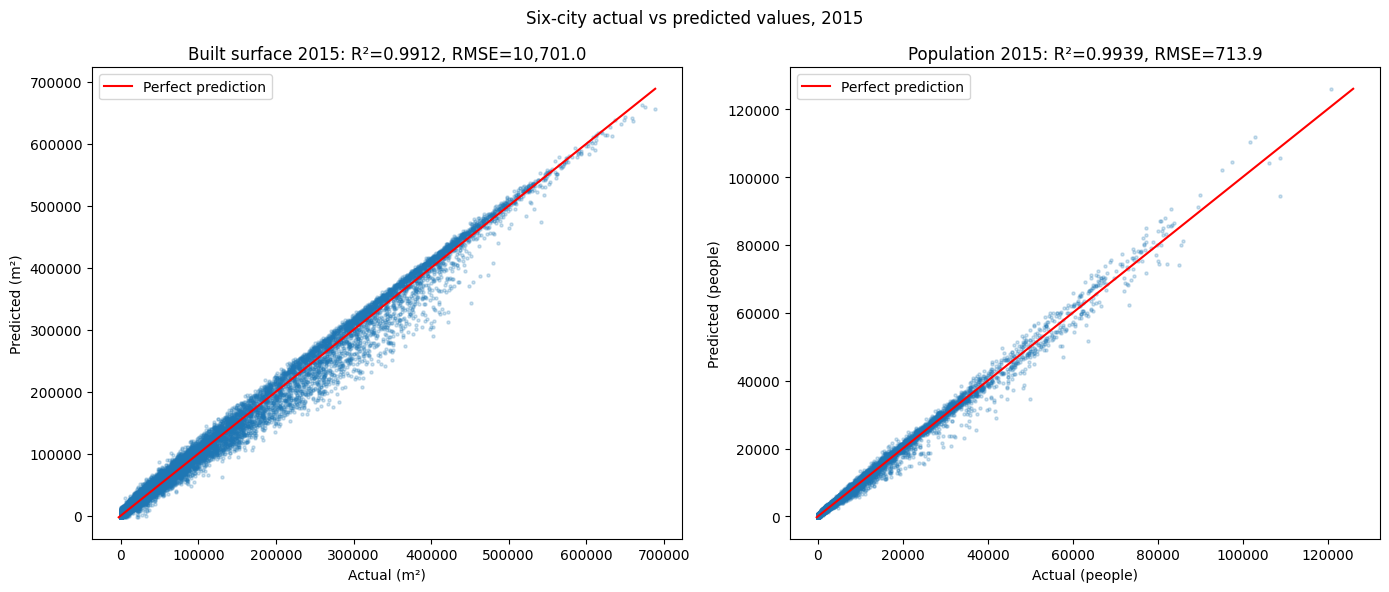

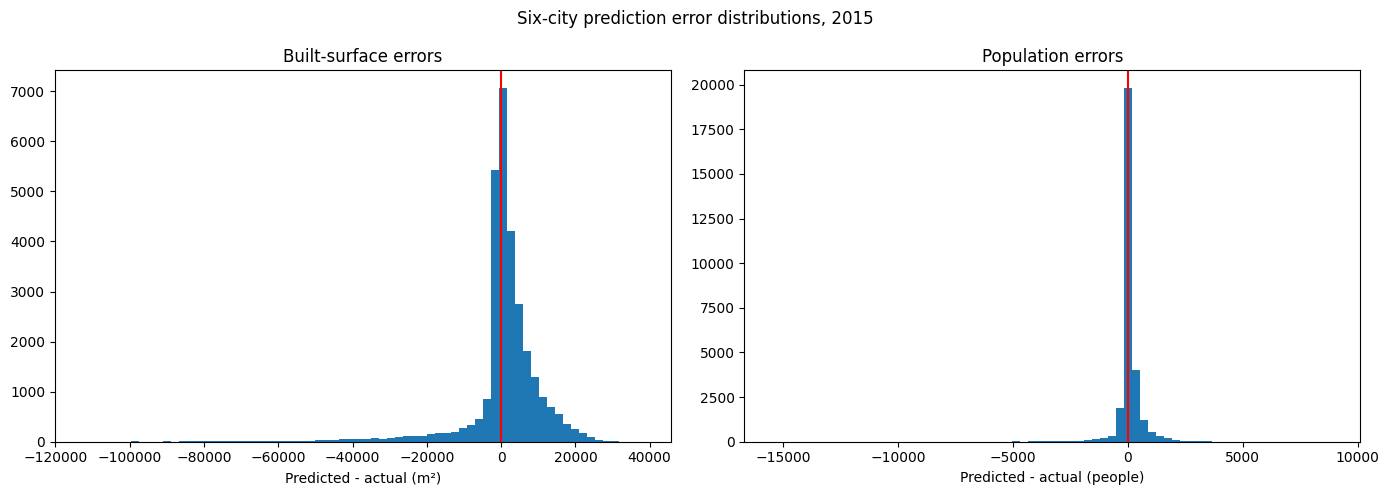

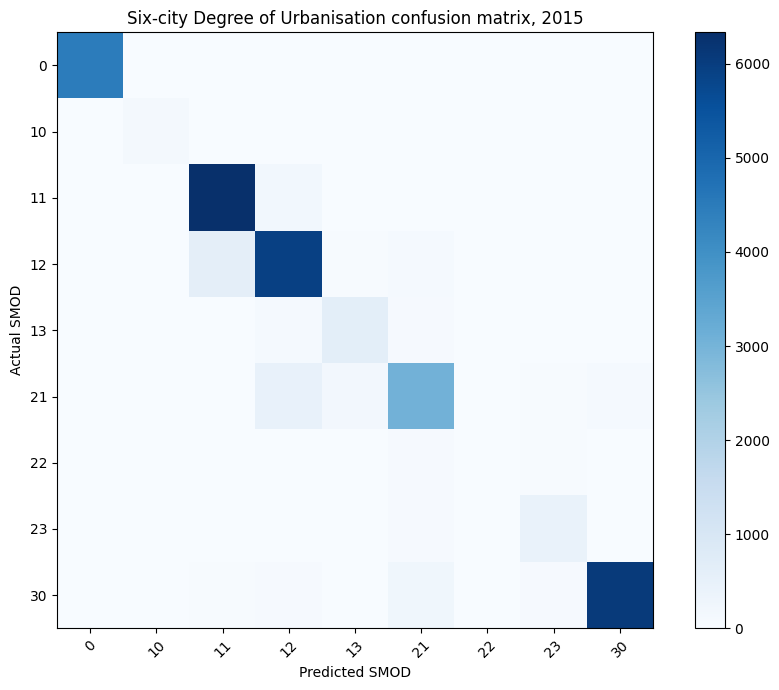

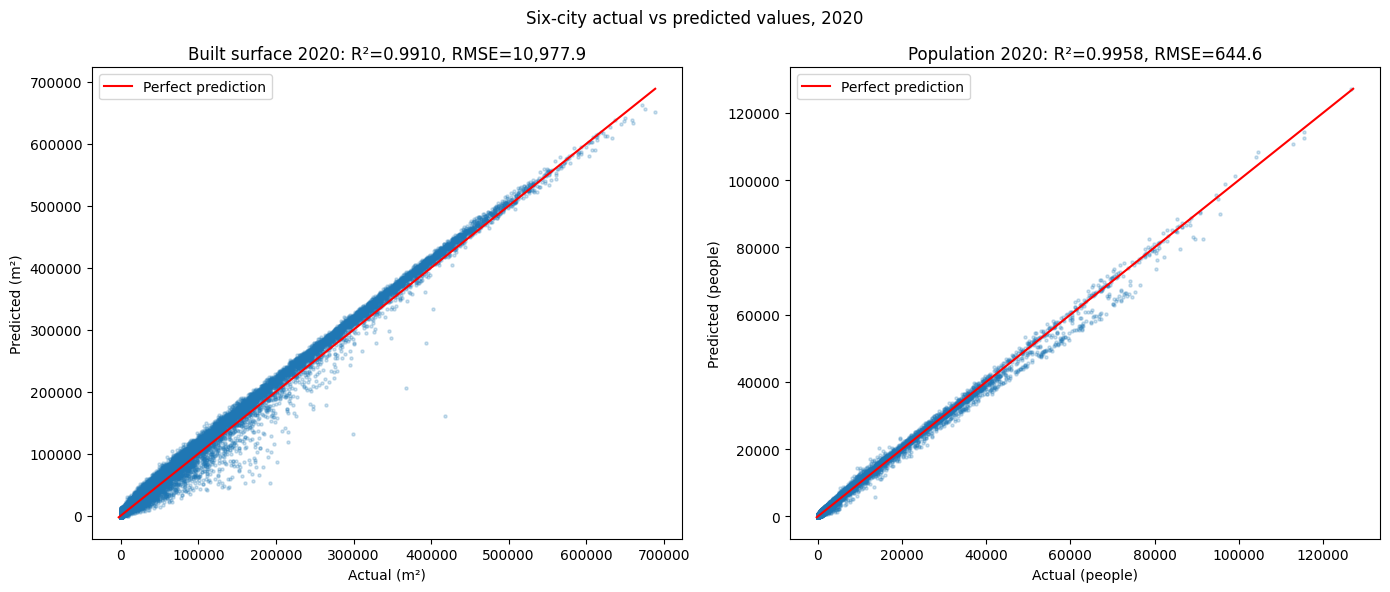

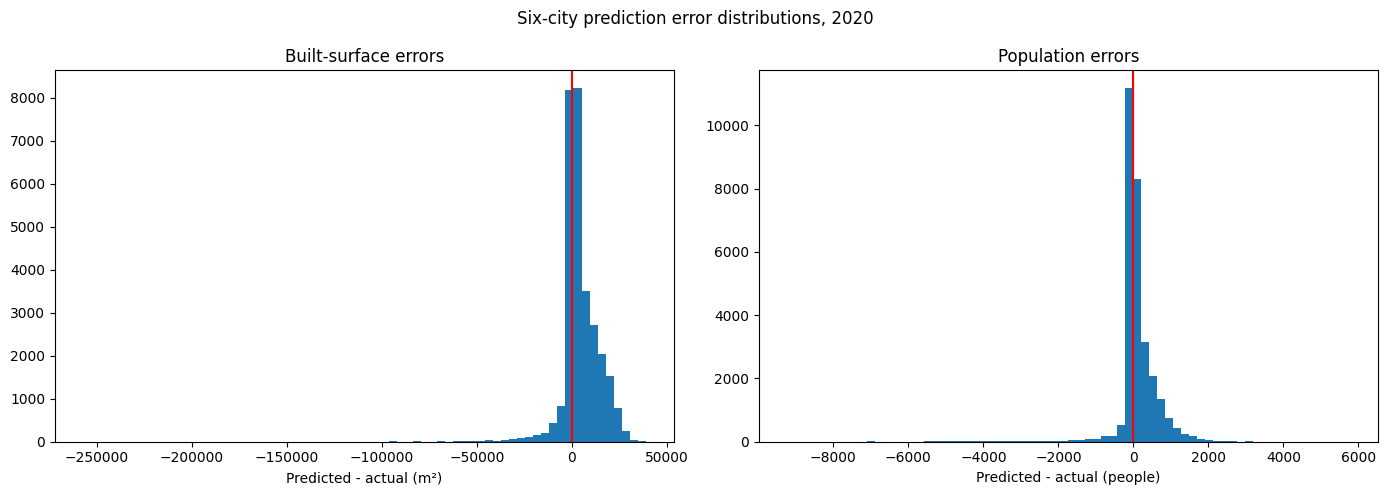

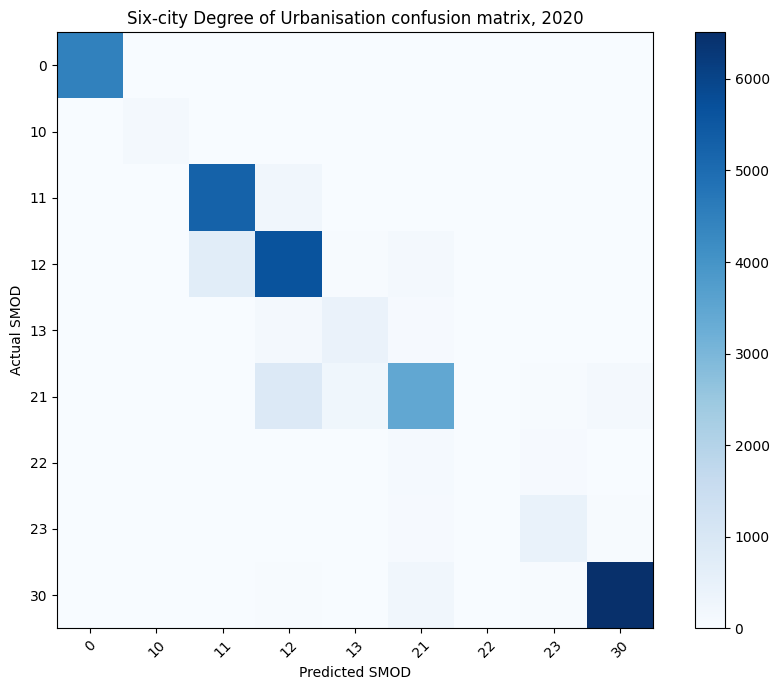

CELL 6: SUCCESS


In [6]:
# ============================================================
# CELL 6: OVERALL SCATTERS, RESIDUALS, METRICS, CONFUSION MATRICES
# ============================================================
def regression_metrics(a,p):
 e=p-a;return {'MAE':np.mean(np.abs(e)),'RMSE':np.sqrt(np.mean(e**2)),'R2':1-np.sum(e**2)/np.sum((a-a.mean())**2),'Bias':np.mean(e)}
for year in [2015,2020]:
 d=pd.read_csv(ART/f'six_city_three_product_{year}_cell_predictions.csv')
 # Two-product observed-vs-predicted panel.
 fig,ax=plt.subplots(1,2,figsize=(14,6))
 for acol,pcol,title,unit,i in [('actual_built_surface_m2','predicted_built_surface_m2','Built surface','m²',0),('actual_population','predicted_population','Population','people',1)]:
  a=d[acol].astype(float);p=d[pcol].astype(float);lo=min(a.min(),p.min());hi=max(a.max(),p.max());ax[i].scatter(a,p,s=5,alpha=.22);ax[i].plot([lo,hi],[lo,hi],color='red',label='Perfect prediction');m=regression_metrics(a,p);ax[i].set_title(f'{title} {year}: R²={m["R2"]:.4f}, RMSE={m["RMSE"]:,.1f}');ax[i].set_xlabel(f'Actual ({unit})');ax[i].set_ylabel(f'Predicted ({unit})');ax[i].legend()
 fig.suptitle(f'Six-city actual vs predicted values, {year}');plt.tight_layout();plt.savefig(FIG/f'overall_actual_vs_predicted_{year}.png',dpi=200);plt.show();plt.close()
 # Residual histograms.
 fig,ax=plt.subplots(1,2,figsize=(14,5));ax[0].hist(d.built_error_m2,bins=70);ax[0].axvline(0,color='red');ax[0].set_title('Built-surface errors');ax[0].set_xlabel('Predicted - actual (m²)');ax[1].hist(d.population_error,bins=70);ax[1].axvline(0,color='red');ax[1].set_title('Population errors');ax[1].set_xlabel('Predicted - actual (people)');fig.suptitle(f'Six-city prediction error distributions, {year}');plt.tight_layout();plt.savefig(FIG/f'overall_error_distributions_{year}.png',dpi=200);plt.show();plt.close()
 # SMOD confusion matrix.
 classes=sorted(set(d.actual_smod_class.astype(str))|set(d.predicted_smod_class.astype(str)),key=lambda x:int(float(x)));cm=pd.crosstab(d.actual_smod_class.astype(str),d.predicted_smod_class.astype(str)).reindex(index=classes,columns=classes,fill_value=0)
 fig,ax=plt.subplots(figsize=(9,7));im=ax.imshow(cm.values,cmap='Blues');ax.set_xticks(range(len(classes)),classes,rotation=45);ax.set_yticks(range(len(classes)),classes);ax.set_xlabel('Predicted SMOD');ax.set_ylabel('Actual SMOD');ax.set_title(f'Six-city Degree of Urbanisation confusion matrix, {year}');fig.colorbar(im,ax=ax);plt.tight_layout();plt.savefig(FIG/f'smod_confusion_{year}.png',dpi=200);plt.show();plt.close()
print('CELL 6: SUCCESS')

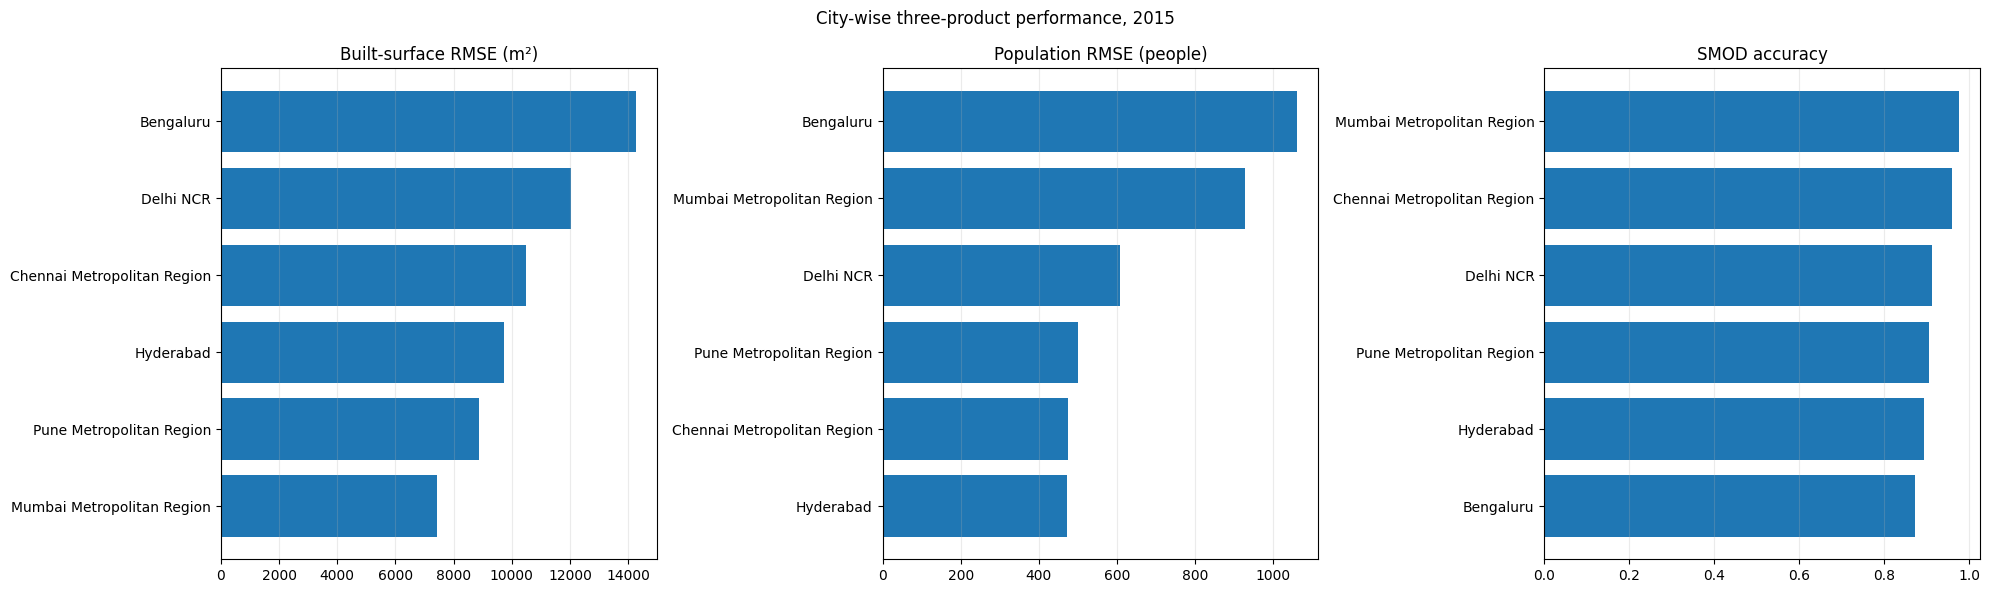

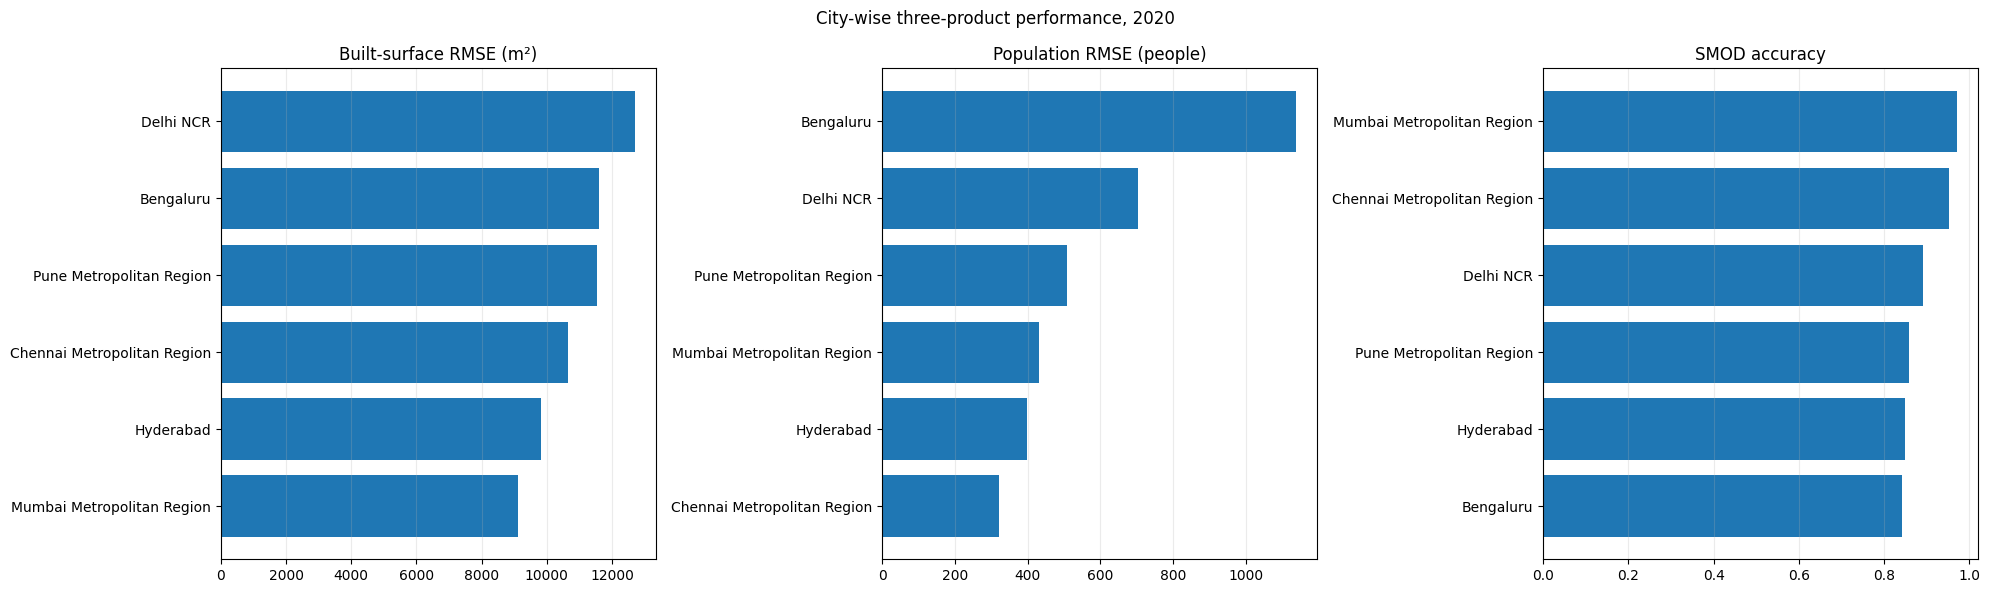

CELL 7: SUCCESS


In [7]:
# ============================================================
# CELL 7: CITY-WISE METRIC AND PERSISTENCE COMPARISON FIGURES
# ============================================================
city=TABLE[TABLE.Scope=='city'].copy()
for year in [2015,2020]:
 d=city[city.Year==year]
 fig,axes=plt.subplots(1,3,figsize=(20,6))
 for product,metric,ax,title in [('Built surface','RMSE',axes[0],'Built-surface RMSE (m²)'),('Population','RMSE',axes[1],'Population RMSE (people)'),('Degree of Urbanisation','R² / Accuracy',axes[2],'SMOD accuracy')]:
  x=d[d.Product==product].sort_values(metric);ax.barh(x.City,x[metric]);ax.set_title(title);ax.grid(axis='x',alpha=.25)
 fig.suptitle(f'City-wise three-product performance, {year}');plt.tight_layout();plt.savefig(FIG/f'citywise_three_product_{year}.png',dpi=200,bbox_inches='tight');plt.show();plt.close()
print('CELL 7: SUCCESS')

In [8]:
# ============================================================
# CELL 8: BEAUTIFUL SPATIAL ACTUAL/PREDICTED/ERROR MAPS
# Creates one three-product figure per city and year.
# ============================================================
for year in [2015,2020]:
 d=pd.read_csv(ART/f'six_city_three_product_{year}_cell_predictions.csv')
 for slug,label in CITY_LABELS.items():
  c=d[d.city_slug==slug].copy()
  if len(c)!=4900:raise RuntimeError(f'{slug} {year}: expected 4900 rows')
  def pivot(col):return c.pivot(index='grid_1km_row',columns='grid_1km_col',values=col).sort_index(ascending=False)
  panels=[('Built surface',pivot('actual_built_surface_m2'),pivot('predicted_built_surface_m2'),'YlOrRd'),('Population',pivot('actual_population'),pivot('predicted_population'),'viridis'),('Degree of Urbanisation',pivot('actual_smod_class'),pivot('predicted_smod_class'),'tab20')]
  fig,axes=plt.subplots(3,3,figsize=(18,16))
  for row,(name,a,p,cmap) in enumerate(panels):
   a=a.astype(float);p=p.astype(float);err=p-a
   if name=='Degree of Urbanisation':vmin=min(np.nanmin(a),np.nanmin(p));vmax=max(np.nanmax(a),np.nanmax(p))
   else:vmin=np.nanpercentile(np.concatenate([a.values.ravel(),p.values.ravel()]),1);vmax=np.nanpercentile(np.concatenate([a.values.ravel(),p.values.ravel()]),99)
   im=axes[row,0].imshow(a,cmap=cmap,vmin=vmin,vmax=vmax);axes[row,0].set_title(f'Actual {name}');fig.colorbar(im,ax=axes[row,0],fraction=.046)
   im=axes[row,1].imshow(p,cmap=cmap,vmin=vmin,vmax=vmax);axes[row,1].set_title(f'Predicted {name}');fig.colorbar(im,ax=axes[row,1],fraction=.046)
   lim=max(abs(np.nanpercentile(err,1)),abs(np.nanpercentile(err,99)),1);im=axes[row,2].imshow(err,cmap='coolwarm',vmin=-lim,vmax=lim);axes[row,2].set_title(f'{name} error');fig.colorbar(im,ax=axes[row,2],fraction=.046)
   for ax in axes[row]:ax.set_axis_off()
  fig.suptitle(f'{label}: actual vs predicted three-product comparison, {year}',fontsize=16);plt.tight_layout();out=SPATIAL/f'{slug}_{year}_three_product_spatial.png';plt.savefig(out,dpi=180,bbox_inches='tight');plt.show();plt.close()
print('Spatial figures created:',len(list(SPATIAL.glob('*.png'))));print('CELL 8: SUCCESS')

Output hidden; open in https://colab.research.google.com to view.

In [9]:
# ============================================================
# CELL 9: GROWTH-HOTSPOT MAPS FOR BUILT SURFACE AND POPULATION
# ============================================================
for year in [2015,2020]:
 d=pd.read_csv(ART/f'six_city_three_product_{year}_cell_predictions.csv')
 for slug,label in CITY_LABELS.items():
  c=d[d.city_slug==slug].copy();k=490
  for prefix,actual_col,pred_col,title in [('built','actual_built_growth_m2','predicted_built_growth_m2','Built-surface growth'),('population','actual_population_change','predicted_population_change','Population growth')]:
   ai=set(c.nlargest(k,actual_col).index);pi=set(c.nlargest(k,pred_col).index);c['actual_hotspot']=c.index.isin(ai);c['predicted_hotspot']=c.index.isin(pi);c['correct_hotspot']=c.index.isin(ai&pi)
   def pivot(col):return c.pivot(index='grid_1km_row',columns='grid_1km_col',values=col).sort_index(ascending=False)
   fig,axes=plt.subplots(1,3,figsize=(16,5));maps=[('Actual top 10%',pivot('actual_hotspot'),'Reds'),('Predicted top 10%',pivot('predicted_hotspot'),'Blues'),('Correct overlap',pivot('correct_hotspot'),'Greens')]
   for ax,(t,m,cm) in zip(axes,maps):ax.imshow(m,cmap=cm,vmin=0,vmax=1);ax.set_title(t);ax.set_axis_off()
   f1=len(ai&pi)/k;fig.suptitle(f'{label} {year} {title} hotspots, F1={f1:.2%}');plt.tight_layout();plt.savefig(SPATIAL/f'{slug}_{year}_{prefix}_hotspots.png',dpi=180,bbox_inches='tight');plt.close()
print('Total spatial/hotspot figures:',len(list(SPATIAL.glob('*.png'))));print('CELL 9: SUCCESS')

Total spatial/hotspot figures: 36
CELL 9: SUCCESS


In [10]:
# ============================================================
# CELL 10: SAVE MANIFEST AND FINAL COMPLETION GATE
# ============================================================
manifest={'created_at_utc':time.strftime('%Y-%m-%dT%H:%M:%SZ',time.gmtime()),'purpose':'Actual-vs-predicted comparison of GHS-BUILT-S, GHS-POP, and GHS-SMOD for six cities in 2015 and 2020','cities':CITY_LABELS,'target_epochs':[2015,2020],'rows_per_epoch':29400,'models':{'built_surface':'Linear Regression','population':'Linear Regression','degree_of_urbanisation':'Random Forest Classifier'},'baselines':{'built_surface':'current built surface','population':'current population','degree_of_urbanisation':'current SMOD class'},'hdfs_combined_predictions':COMBINED,'hdfs_summary':SUMMARY,'drive_output':str(ART),'figure_count':len(list(FIG.rglob('*.png'))),'source_datasets_modified':False}
(ART/'six_city_three_product_evaluation_manifest.json').write_text(json.dumps(manifest,indent=2,sort_keys=True)+'\n')
print('Six cities: 6/6')
print('2015 validation comparison: COMPLETE')
print('2020 test comparison: COMPLETE')
print('Built-surface predicted vs actual: COMPLETE')
print('Population predicted vs actual: COMPLETE')
print('Degree of Urbanisation predicted vs actual: COMPLETE')
print('Persistence comparisons: COMPLETE')
print('Overall figures: COMPLETE')
print('City-wise spatial figures: COMPLETE')
print('Growth-hotspot figures: COMPLETE')
print('Source datasets modified: NO')
print('NOTEBOOK_17_SIX_CITY_THREE_PRODUCT_EVALUATION_SUCCESS')
print('CELL 10: SUCCESS')

Six cities: 6/6
2015 validation comparison: COMPLETE
2020 test comparison: COMPLETE
Built-surface predicted vs actual: COMPLETE
Population predicted vs actual: COMPLETE
Degree of Urbanisation predicted vs actual: COMPLETE
Persistence comparisons: COMPLETE
Overall figures: COMPLETE
City-wise spatial figures: COMPLETE
Growth-hotspot figures: COMPLETE
Source datasets modified: NO
NOTEBOOK_17_SIX_CITY_THREE_PRODUCT_EVALUATION_SUCCESS
CELL 10: SUCCESS


Completed evaluation
Product	Model	Validation	Test	Baseline
Built surface	Linear Regression	2010→2015	2015→2020	Current built surface
Population	Linear Regression	2010→2015	2015→2020	Current population
Degree of Urbanisation	Random Forest	2010→2015	2015→2020	Current SMOD class

The evaluation covers:

6 cities

29,400 cells for 2015

29,400 cells for 2020

58,800 combined cell-period comparisons

Actual-versus-predicted values

Persistence comparisons

Built-surface and population growth hotspots

SMOD confusion matrices

City-wise spatial error maps

Where the results are stored

Google Drive


/content/drive/MyDrive/GHSL_Urban_Growth_Model/
six_city_three_product_evaluation_v1/

Key artifacts:


six_city_three_product_2015_cell_predictions.csv

six_city_three_product_2020_cell_predictions.csv

three_product_metrics.csv

three_product_metrics.json

smod_confusion.csv

six_city_three_product_evaluation_manifest.json



/content/drive/MyDrive/GHSL_Urban_Growth_Model/
six_city_three_product_evaluation_v1/figures/

Overall figures:


overall_actual_vs_predicted_2015.png

overall_actual_vs_predicted_2020.png

overall_error_distributions_2015.png

overall_error_distributions_2020.png

smod_confusion_2015.png

smod_confusion_2020.png

citywise_three_product_2015.png

citywise_three_product_2020.png

City-specific maps are under:

Plain Text
.../figures/spatial/